# Import libraries

In [4]:
!git clone https://github.com/arvindbitm/PhiUSIIL.git
!ls PhiUSIIL

fatal: destination path 'PhiUSIIL' already exists and is not an empty directory.
CharConRate.ipynb	   MainModel_SplitBased_OneTime90.ipynb
Entropy_Domain_URL.ipynb   URL_Info_WhoIS.ipynb
IdentifyClassifiers.ipynb  WebPageTitleMatchScore.ipynb


In [5]:

!pip -q install ucimlrepo pandas numpy scikit-learn matplotlib joblib

In [13]:
#*****************************************Import********************************************
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import PassiveAggressiveClassifier, SGDClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             classification_report)

# Load Dataset

In [14]:
source = fetch_ucirepo(id=967)

X = source.data.features
y = source.data.targets

# Combine features and target into one dataframe
df = pd.concat([X, y], axis=1)
df.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


# Data Cleaning & Preprocessing

In [15]:
df = pd.concat([source.data.features, source.data.targets], axis=1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
print('Rows, columns (excluding FILENAME):', df.shape)
print('Labels (0=phishing, 1=legitimate):\n', df['label'].value_counts())

Rows, columns (excluding FILENAME): (235795, 55)
Labels (0=phishing, 1=legitimate):
 label
1    134850
0    100945
Name: count, dtype: int64


In [16]:
# Same feature list as the original MainModel notebook (30 inputs + label? verified below).
FEATURES = [
    'LineOfCode', 'NoOfExternalRef', 'LargestLineLength', 'URLLength',
    'NoOfImage', 'NoOfJS', 'NoOfSelfRef', 'NoOfCSS',
    'URLCharProb', 'CharContinuationRate', 'LetterRatioInURL', 'IsHTTPS',
    'SpacialCharRatioInURL', 'NoOfEmptyRef', 'NoOfOtherSpecialCharsInURL',
    'HasDescription', 'HasSocialNet', 'DomainLength', 'DegitRatioInURL',
    'NoOfDegitsInURL', 'HasCopyrightInfo', 'NoOfLettersInURL',
    'TLDLegitimateProb', 'DomainTitleMatchScore', 'IsResponsive',
    'HasHiddenFields', 'HasSubmitButton', 'NoOfSubDomain',
    'HasFavicon', 'HasTitle'
]
missing = sorted(set(FEATURES + ['label']) - set(df.columns))
assert not missing, f'Missing columns: {missing}'

selected = df[FEATURES + ['label']].copy()
# Original: test_size=.1 with no fixed seed. Fixed seed is added for reproducibility.
train_df, stream_df = train_test_split(selected, test_size=0.1, random_state=42)
X_train = train_df[FEATURES]
y_train = train_df['label'].to_numpy()
X_stream = stream_df[FEATURES].to_numpy()
y_stream = stream_df['label'].to_numpy()
print('Selected features:', len(FEATURES))
print('Initial training:', len(train_df), 'Sequential evaluation:', len(stream_df))

Selected features: 30
Initial training: 212215 Sequential evaluation: 23580


# Classifier Families

In [17]:
# Original classifier families and hyperparameters
models = [
    ('BernoulliNB', BernoulliNB(alpha=0.01, binarize=0.0,
                                fit_prior=False)),
    ('PassiveAggressive', PassiveAggressiveClassifier(
        C=4, fit_intercept=False, n_iter_no_change=50, n_jobs=10,
        shuffle=True, random_state=42)),
    ('SGDClassifier', SGDClassifier(
        alpha=0.01, eta0=100, n_iter_no_change=50,
        n_jobs=1, random_state=42))
]
start = time.perf_counter()
for name, model in models:
    model.fit(X_train, y_train)
initial_training_seconds = time.perf_counter() - start
print(f'Initial training complete: {initial_training_seconds:.1f} sec')

Initial training complete: 31.5 sec


# Incremental learning

In [18]:
# Predict each URL, then update each model with its true label (online learning).
# Votes count predictions of class 1 (legitimate).
records = []
correct_best = 0
start = time.perf_counter()
for i, (x, true_label) in enumerate(zip(X_stream, y_stream), start=1):
    xi = x.reshape(1, -1)
    yi = np.array([true_label])
    individual_predictions = {}
    for name, model in models:
        individual_predictions[name] = int(model.predict(xi)[0])
        model.partial_fit(xi, yi, classes=np.array([0, 1]))

    votes = sum(individual_predictions.values())
    low = int(votes >= 1)   # At least one vote for legitimate
    best = int(votes >= 2)  # Majority vote
    high = int(votes == 3)  # All votes for legitimate
    correct_best += int(best == true_label)
    records.append({
        'label': int(true_label),
        **individual_predictions,
        'votes_for_legitimate': votes,
        'LowSecurity': low,
        'BestSecurity': best,
        'HighSecurity': high,
        'running_accuracy': correct_best / i
    })
    if i % 5000 == 0:
        print(f'Processed {i:,}/{len(X_stream):,} examples')

incremental_seconds = time.perf_counter() - start
results = pd.DataFrame.from_records(records)
results.to_csv('PhiUSIIL_predictions.csv', index=False)
print(f'Sequential evaluation complete: {incremental_seconds:.1f} sec')

Processed 5,000/23,580 examples
Processed 10,000/23,580 examples
Processed 15,000/23,580 examples
Processed 20,000/23,580 examples
Sequential evaluation complete: 87.8 sec


# Results

,Mode,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Legitimate_F1,MCC
0,LowSecurity,0.98664,0.99990,0.96863,0.98402,0.98853,0.97291
1,BestSecurity,0.99843,0.99820,0.99810,0.99815,0.99864,0.99679
2,HighSecurity,0.99190,0.98128,1.00000,0.99055,0.99291,0.98360


BestSecurity confusion matrix (rows=true, cols=predicted; [0,1]):
[[ 9991    19]
 [   18 13552]]
                precision    recall  f1-score   support

  Phishing (0)       1.00      1.00      1.00     10010
Legitimate (1)       1.00      1.00      1.00     13570

      accuracy                           1.00     23580
     macro avg       1.00      1.00      1.00     23580
  weighted avg       1.00      1.00      1.00     23580

Initial training: 31.5s; online processing: 87.8s


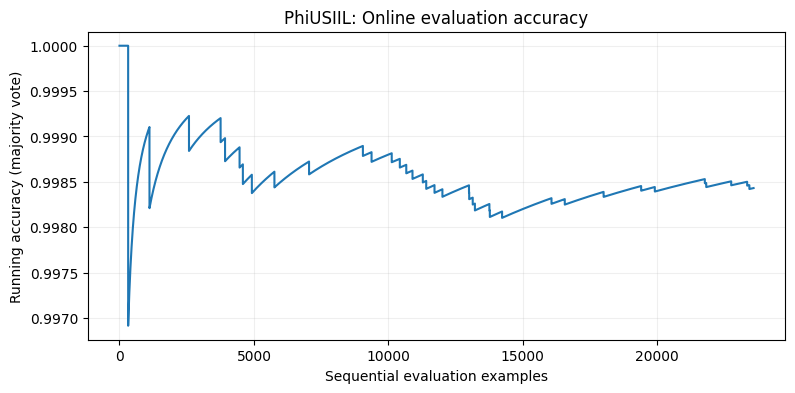

In [19]:
# Show all three voting modes. Main phishing metrics use positive label 0.
rows = []
for mode in ['LowSecurity', 'BestSecurity', 'HighSecurity']:
    pred = results[mode]
    rows.append({
        'Mode': mode,
        'Accuracy': accuracy_score(results['label'], pred),
        'Phishing_Precision': precision_score(results['label'], pred, pos_label=0),
        'Phishing_Recall': recall_score(results['label'], pred, pos_label=0),
        'Phishing_F1': f1_score(results['label'], pred, pos_label=0),
        'Legitimate_F1': f1_score(results['label'], pred, pos_label=1),
        'MCC': matthews_corrcoef(results['label'], pred),
    })
summary = pd.DataFrame(rows)
summary.to_csv('PhiUSIIL_metrics.csv', index=False)
display(summary.round(5))
print('BestSecurity confusion matrix (rows=true, cols=predicted; [0,1]):')
print(confusion_matrix(results['label'], results['BestSecurity'], labels=[0,1]))
print(classification_report(results['label'], results['BestSecurity'],
                            labels=[0,1], target_names=['Phishing (0)', 'Legitimate (1)']))
print(f'Initial training: {initial_training_seconds:.1f}s; online processing: {incremental_seconds:.1f}s')

plt.figure(figsize=(9, 4))
plt.plot(results['running_accuracy'])
plt.xlabel('Sequential evaluation examples')
plt.ylabel('Running accuracy (majority vote)')
plt.title('PhiUSIIL: Online evaluation accuracy')
plt.grid(alpha=0.2)
plt.show()